# Proyecto de Big Data: Análisis y predicción de tarifas de NYC Yellow Taxi

## Configuración del entorno

In [1]:
# Instalar Java 17
!apt-get install openjdk-17-jdk-headless -qq

# Configurar Java
import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"

# Instalar PySpark
!pip install pyspark==3.5.1

#Librerias
# Generales
import glob
import os
from functools import reduce

from google.colab import drive
drive.mount('/content/drive')

# PySpark - Sesión y procesamiento de datos
from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    sum, col, unix_timestamp,
    hour, dayofweek, count,
    month, rand, year,
    abs, avg, to_date,
    max, min, expr, date_format
)

# PySpark - Machine Learning
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    VectorAssembler
)
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

# Otras librerías
import matplotlib.pyplot as plt
import pandas as pd

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 317.0/317.0 MB 2.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.5/200.5 kB 8.6 MB/s eta 0:00:00
  Created wheel for pyspark: filename=pyspark-3.5.1-py2.py3-none-any.whl size=317488493 sha256=7ee1f57937ff5d20ffd7de9d0ce00d424fd7bb4263fd6d4f67d4588097a49b7e
  Stored in directory: /root/.cache/pip/wheels/b1/91/5f/283b53010a8016a4ff1c4a1edd99bbe73afacb099645b5471b
Successfully built pyspark
  Attempting uninstall: py4j
    Found existing installation: py4j 0.10.9.9
    Uninstalling py4j-0.10.9.9:
      Successfully uninstalled py4j-0.10.9.9
  Attempting uninstall: pyspark
    Found existing installation: pyspark 4.0.3
    Uninstalling pyspark-4.0.3:
      Successfully uninstalled pyspark-4.0.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-conne

## Localización de Archivos

Se descargan 24 archivos, cada archivo contiene un mes de NYC TLC. (Info de 2024 y 2025)

In [31]:
import numpy as np
ruta = "/content/drive/MyDrive/Concentración IA Avanzada/Periodo Avanzado/Proyecto Big Data/yellow_taxi"
archivos = glob.glob(os.path.join(ruta, "*.parquet"))

print("Archivos encontrados:", len(archivos))
peso = np.sum(os.path.getsize(f) for f in archivos)

for archivo in archivos:
    print(os.path.basename(archivo))


print(
    "Tamaño Parquet limpio:",
    round(peso / (1024**3), 2),
    "GB"
)

Archivos encontrados: 24
yellow_tripdata_2024-01.parquet
yellow_tripdata_2024-02.parquet
yellow_tripdata_2024-03.parquet
yellow_tripdata_2024-04.parquet
yellow_tripdata_2024-05.parquet
yellow_tripdata_2024-06.parquet
yellow_tripdata_2024-07.parquet
yellow_tripdata_2024-08.parquet
yellow_tripdata_2024-09.parquet
yellow_tripdata_2024-10.parquet
yellow_tripdata_2024-11.parquet
yellow_tripdata_2024-12.parquet
yellow_tripdata_2025-01.parquet
yellow_tripdata_2025-02.parquet
yellow_tripdata_2025-03.parquet
yellow_tripdata_2025-04.parquet
yellow_tripdata_2025-05.parquet
yellow_tripdata_2025-06.parquet
yellow_tripdata_2025-07.parquet
yellow_tripdata_2025-08.parquet
yellow_tripdata_2025-09.parquet
yellow_tripdata_2025-10.parquet
yellow_tripdata_2025-11.parquet
yellow_tripdata_2025-12.parquet
Tamaño Parquet limpio: 1.42 GB


/tmp/ipykernel_356/1131913422.py:6: DeprecationWarning: Calling np.sum(generator) is deprecated, and in the future will give a different result. Use np.sum(np.fromiter(generator)) or the python sum builtin instead.
  peso = np.sum(os.path.getsize(f) for f in archivos)


### Inicio de SparkSession

In [3]:
spark = SparkSession.builder \
    .appName("NYC_Taxi_BigData_Regression") \
    .master("local[*]") \
    .config("spark.driver.memory", "6g") \
    .config("spark.sql.shuffle.partitions", "8") \
    .getOrCreate()

print("Versión de Spark:", spark.version)
print("Sesión activa:", spark.sparkContext.appName)
print("Número de núcleos:", spark.sparkContext.defaultParallelism)

Versión de Spark: 3.5.1
Sesión activa: NYC_Taxi_BigData_Regression
Número de núcleos: 2


### Lectura de archivos

In [4]:
columnas = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "passenger_count",
    "trip_distance",
    "PULocationID",
    "DOLocationID",
    "fare_amount"
]

dataframes = []

for archivo in archivos:

    print("Procesando - ", archivo.split("/")[-1])

    temporal = spark.read.parquet(archivo)

    # Seleccionar únicamente las columnas necesarias
    temporal = temporal.select(*columnas)

    dataframes.append(temporal)

# Unificar todos los archivos
df = reduce(
    lambda a, b: a.unionByName(b),
    dataframes
)

Procesando -  yellow_tripdata_2024-01.parquet
Procesando -  yellow_tripdata_2024-02.parquet
Procesando -  yellow_tripdata_2024-03.parquet
Procesando -  yellow_tripdata_2024-04.parquet
Procesando -  yellow_tripdata_2024-05.parquet
Procesando -  yellow_tripdata_2024-06.parquet
Procesando -  yellow_tripdata_2024-07.parquet
Procesando -  yellow_tripdata_2024-08.parquet
Procesando -  yellow_tripdata_2024-09.parquet
Procesando -  yellow_tripdata_2024-10.parquet
Procesando -  yellow_tripdata_2024-11.parquet
Procesando -  yellow_tripdata_2024-12.parquet
Procesando -  yellow_tripdata_2025-01.parquet
Procesando -  yellow_tripdata_2025-02.parquet
Procesando -  yellow_tripdata_2025-03.parquet
Procesando -  yellow_tripdata_2025-04.parquet
Procesando -  yellow_tripdata_2025-05.parquet
Procesando -  yellow_tripdata_2025-06.parquet
Procesando -  yellow_tripdata_2025-07.parquet
Procesando -  yellow_tripdata_2025-08.parquet
Procesando -  yellow_tripdata_2025-09.parquet
Procesando -  yellow_tripdata_2025

## Exploración de Datos

In [5]:
# Número total de registros
print("Total de registros:", df.count())

# Número de columnas
print("Total de columnas:", len(df.columns))

# Estructura de la base
df.printSchema()

# Mostrar primeros registros
df.show(10, truncate=False)


Total de registros: 89892322
Total de columnas: 7
root
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- fare_amount: double (nullable = true)

+--------------------+---------------------+---------------+-------------+------------+------------+-----------+
|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|PULocationID|DOLocationID|fare_amount|
+--------------------+---------------------+---------------+-------------+------------+------------+-----------+
|2024-01-01 00:57:55 |2024-01-01 01:17:43  |1              |1.72         |186         |79          |17.7       |
|2024-01-01 00:03:00 |2024-01-01 00:09:36  |1              |1.8          |140         |236         |10.0       |
|2024-01-01 00:17:06 |2024-01-01 00:3

In [6]:
df.describe(
    "passenger_count",
    "trip_distance",
    "fare_amount"
).show()

nulos = df.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in df.columns
])

nulos.show()

+-------+------------------+-----------------+------------------+
|summary|   passenger_count|    trip_distance|       fare_amount|
+-------+------------------+-----------------+------------------+
|  count|          74189196|         89892322|          89892322|
|   mean|1.3147025612732075|5.987921641071738| 18.80826993933856|
| stddev|0.7739282157205494|555.9173867114913|117.28427721523518|
|    min|                 0|              0.0|           -2261.2|
|    max|                 9|        398608.62|         863372.12|
+-------+------------------+-----------------+------------------+

+--------------------+---------------------+---------------+-------------+------------+------------+-----------+
|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|PULocationID|DOLocationID|fare_amount|
+--------------------+---------------------+---------------+-------------+------------+------------+-----------+
|                   0|                    0|       15703126|      

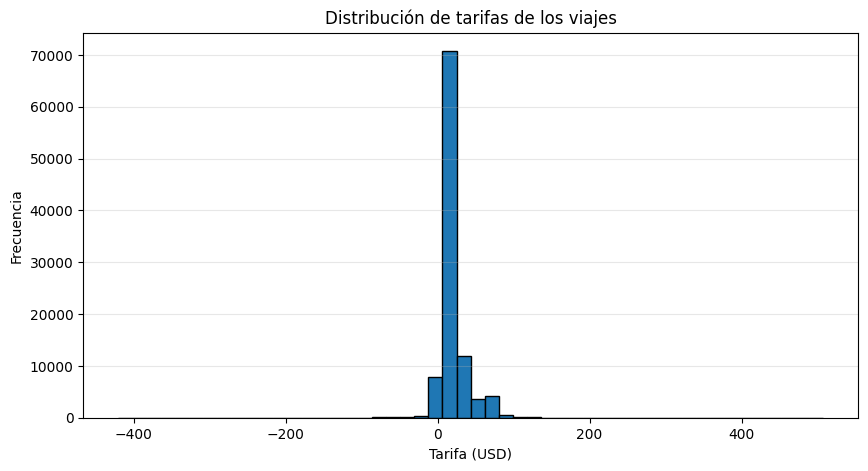

In [7]:
# Tomar una muestra de los datos originales para visualizar la distribución de tarifas

muestra_tarifas = (
    df.select("fare_amount")
    .sample(False, 0.002, seed=42)
    .limit(100000)
    .toPandas()
)
plt.figure(figsize=(10,5))

plt.hist(
    muestra_tarifas["fare_amount"].dropna(),
    bins=50,
    edgecolor="black"
)

plt.title("Distribución de tarifas de los viajes")
plt.xlabel("Tarifa (USD)")
plt.ylabel("Frecuencia")
plt.grid(axis="y", alpha=0.3)

plt.show()

## Limpieza de Datos

In [8]:
df_limpio = df.dropna(
    subset=[
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "passenger_count",
        "trip_distance",
        "fare_amount",
        "PULocationID",
        "DOLocationID"
    ]
)

df_limpio = df_limpio.filter(
    (col("trip_distance") > 0.1) &
    (col("trip_distance") <= 100) &
    (col("fare_amount") >= 2.5) &
    (col("fare_amount") <= 150) &
    (col("passenger_count") >= 1) &
    (col("passenger_count") <= 6) &
    (col("fare_amount") / col("trip_distance") <= 20)
)

print("Registros originales:", df.count())
print("Registros después de limpieza:", df_limpio.count())
print(f" Se redujo un {round((df.count() - df_limpio.count()) / df.count() * 100,2)}%")

Registros originales: 89892322
Registros después de limpieza: 69846043
 Se redujo un 22.3%


## Feature Engineering (Generación de Nuevas Variables)

In [9]:
df_limpio_2 = df_limpio
df_limpio = df_limpio.withColumn(
    "trip_duration_min",
    (
        unix_timestamp("tpep_dropoff_datetime") -
        unix_timestamp("tpep_pickup_datetime")
    ) / 60
)

df_limpio = df_limpio.withColumn(
    "pickup_hour",
    hour("tpep_pickup_datetime")
)

df_limpio = df_limpio.withColumn(
    "pickup_day",
    dayofweek("tpep_pickup_datetime")
)

df_limpio = df_limpio.withColumn(
    "pickup_month",
    month("tpep_pickup_datetime")
)

df_limpio = df_limpio.filter(
    (col("trip_duration_min") > 0) &
    (col("trip_duration_min") <= 180)
)

# Variables temporales para Visualización en Tableau
# Año del viaje
df_limpio = df_limpio.withColumn(
    "pickup_year",
    year("tpep_pickup_datetime")
)

# Fecha completa
df_limpio = df_limpio.withColumn(
    "pickup_date",
    to_date("tpep_pickup_datetime")
)

# Año y mes (formato YYYY-MM)
df_limpio = df_limpio.withColumn(
    "pickup_year_month",
    date_format("tpep_pickup_datetime", "yyyy-MM")
)

# Nombre del día de la semana
df_limpio = df_limpio.withColumn(
    "pickup_weekday",
    date_format("tpep_pickup_datetime", "EEEE")
)

# Número del día de la semana
df_limpio = df_limpio.withColumn(
    "pickup_weekday_num",
    dayofweek("tpep_pickup_datetime")
)

df_limpio.show(10, truncate=False)

+--------------------+---------------------+---------------+-------------+------------+------------+-----------+------------------+-----------+----------+------------+-----------+-----------+-----------------+--------------+------------------+
|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|PULocationID|DOLocationID|fare_amount|trip_duration_min |pickup_hour|pickup_day|pickup_month|pickup_year|pickup_date|pickup_year_month|pickup_weekday|pickup_weekday_num|
+--------------------+---------------------+---------------+-------------+------------+------------+-----------+------------------+-----------+----------+------------+-----------+-----------+-----------------+--------------+------------------+
|2024-01-01 00:57:55 |2024-01-01 01:17:43  |1              |1.72         |186         |79          |17.7       |19.8              |0          |2         |1           |2024       |2024-01-01 |2024-01          |Monday        |2                 |
|2024-01-01 00:03:00 |20

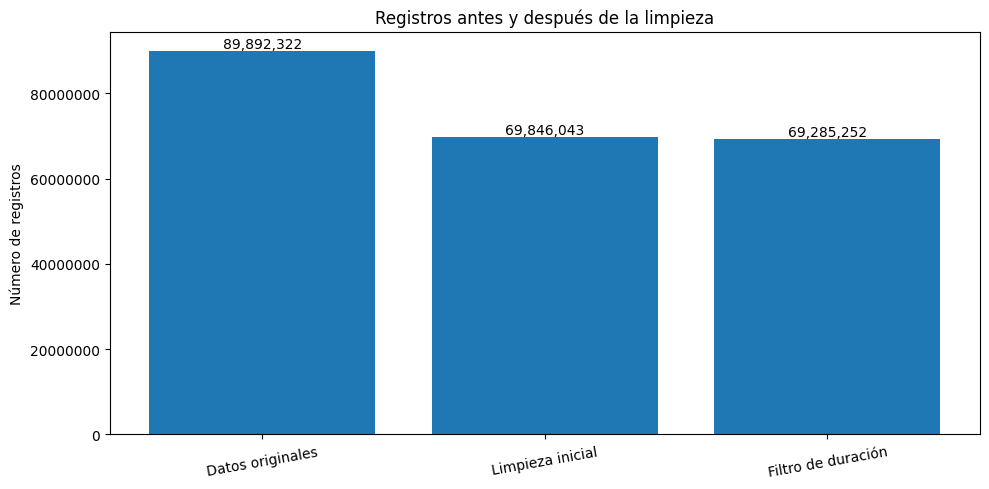

In [10]:
etapas = [
    "Datos originales",
    "Limpieza inicial",
    "Filtro de duración"
]

registros_originales = df.count()
registros_limpios = df_limpio_2.count()
registros_duracion = df_limpio.count()

cantidades = [
    registros_originales,
    registros_limpios,
    registros_duracion
]

plt.figure(figsize=(10,5))

barras = plt.bar(etapas, cantidades)

plt.title("Registros antes y después de la limpieza")
plt.ylabel("Número de registros")

plt.ticklabel_format(
    axis="y",
    style="plain"
)

plt.xticks(rotation=10)

for barra, cantidad in zip(barras, cantidades):
    plt.text(
        barra.get_x() + barra.get_width()/2,
        barra.get_height(),
        f"{cantidad:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

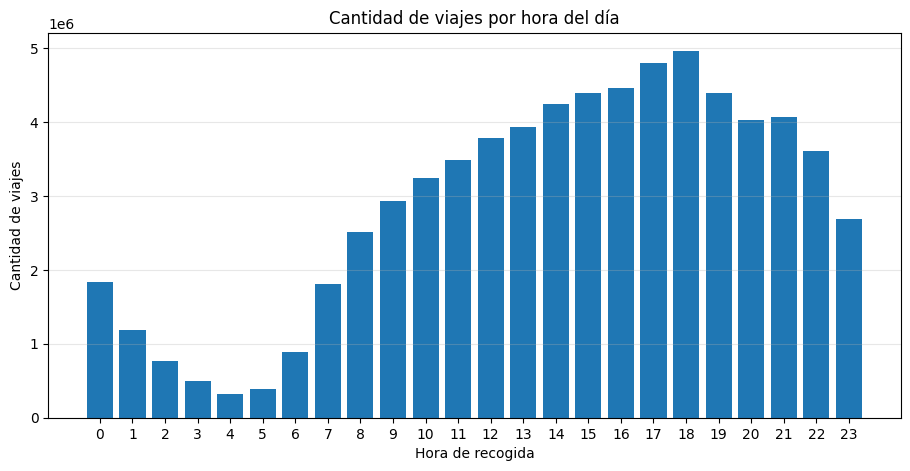

In [11]:
# Agrupar los viajes por hora de recogida

viajes_hora = (
    df_limpio
    .groupBy("pickup_hour")
    .count()
    .orderBy("pickup_hour")
    .toPandas()
)

plt.figure(figsize=(11,5))

plt.bar(
    viajes_hora["pickup_hour"],
    viajes_hora["count"]
)

plt.title("Cantidad de viajes por hora del día")
plt.xlabel("Hora de recogida")
plt.ylabel("Cantidad de viajes")

plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)

plt.show()

In [12]:
# Número total de registros
print("Total de registros:", df_limpio.count())

# Número de columnas
print("Total de columnas:", len(df_limpio.columns))

# Estructura de la base
df_limpio.printSchema()

Total de registros: 69285252
Total de columnas: 16
root
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- trip_duration_min: double (nullable = true)
 |-- pickup_hour: integer (nullable = true)
 |-- pickup_day: integer (nullable = true)
 |-- pickup_month: integer (nullable = true)
 |-- pickup_year: integer (nullable = true)
 |-- pickup_date: date (nullable = true)
 |-- pickup_year_month: string (nullable = true)
 |-- pickup_weekday: string (nullable = true)
 |-- pickup_weekday_num: integer (nullable = true)



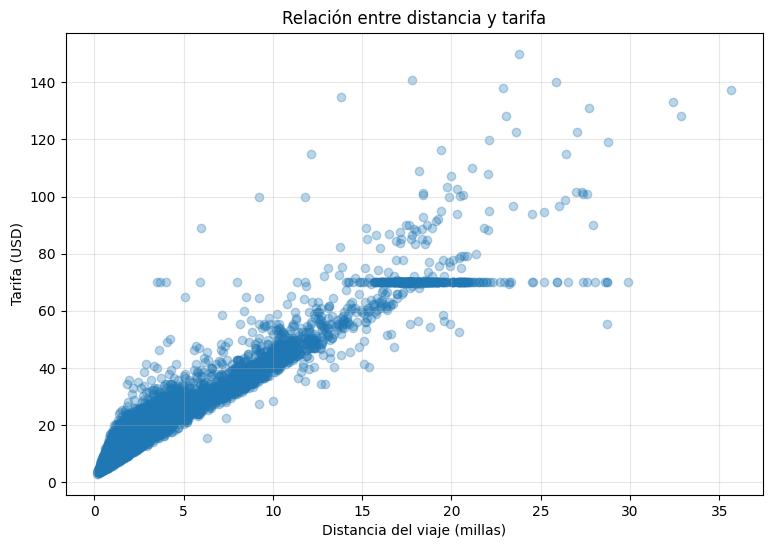

In [13]:
muestra_distancia = (
    df_limpio
    .select("trip_distance", "fare_amount")
    .sample(False, 0.001, seed=42)
    .limit(10000)
    .toPandas()
)

plt.figure(figsize=(9,6))

plt.scatter(
    muestra_distancia["trip_distance"],
    muestra_distancia["fare_amount"],
    alpha=0.3
)

plt.title("Relación entre distancia y tarifa")
plt.xlabel("Distancia del viaje (millas)")
plt.ylabel("Tarifa (USD)")

plt.grid(alpha=0.3)
plt.show()

In [ ]:
#Extracción de Datos limpios
ruta_salida = "/content/drive/MyDrive/Concentración IA Avanzada/Periodo Avanzado/Proyecto Big Data/nyc_taxi_clean"

df_limpio.write \
    .mode("overwrite") \
    .parquet(ruta_salida)

tamano_gb = os.path.getsize(ruta_salida) / (1024 ** 3)
print(f"Datos limpios guardados correctamente. Tamaño: {tamano_gb:.4f} GB")

Datos limpios guardados correctamente.


In [22]:
import numpy as np
ruta_salida = "/content/drive/MyDrive/Concentración IA Avanzada/Periodo Avanzado/Proyecto Big Data/nyc_taxi_clean"
archivos_limpios = glob.glob(
    os.path.join(ruta_salida, "*.parquet")
)

peso_limpio = np.sum(os.path.getsize(f) for f in archivos_limpios)

print(
    "Tamaño Parquet limpio:",
    round(peso_limpio / (1024**3), 2),
    "GB"
)

Tamaño Parquet limpio: 1.12 GB


/tmp/ipykernel_356/296614511.py:7: DeprecationWarning: Calling np.sum(generator) is deprecated, and in the future will give a different result. Use np.sum(np.fromiter(generator)) or the python sum builtin instead.
  peso_limpio = np.sum(os.path.getsize(f) for f in archivos_limpios)


## Preparación de datos para Tableau

In [23]:
ruta_tableau = "/content/drive/MyDrive/Concentración IA Avanzada/Periodo Avanzado/Proyecto Big Data/tableau_exports"

os.makedirs(ruta_tableau, exist_ok=True)

# Filtrar años del proyecto
df_periodo = df_limpio.filter(
    year("tpep_pickup_datetime").isin(2024, 2025)
)

# Agregar información por fecha y hora
df_tableau_tiempo = (
    df_periodo
    .groupBy(
        "pickup_date",
        "pickup_year",
        "pickup_month",
        "pickup_year_month",
        "pickup_hour",
        "pickup_weekday",
        "pickup_weekday_num"
    )
    .agg(
        count("*").alias("total_viajes"),
        avg("fare_amount").alias("tarifa_promedio"),
        avg("trip_distance").alias("distancia_promedio"),
        avg("trip_duration_min").alias("duracion_promedio")
    )
)

df_tableau_tiempo = df_tableau_tiempo.orderBy(
    "pickup_date",
    "pickup_hour"
)

df_tableau_tiempo.coalesce(1).write \
    .mode("overwrite") \
    .option("header", True) \
    .csv(os.path.join(ruta_tableau, "viajes_tiempo"))

print("CSV de viajes por tiempo generado correctamente.")


CSV de viajes por tiempo generado correctamente.


In [28]:
# Agregar dimensiones temporales y zona

df_tableau_zonas = (
    df_periodo
    .withColumn(
        "pickup_year",
        year("tpep_pickup_datetime")
    )
    .withColumn(
        "pickup_month",
        month("tpep_pickup_datetime")
    )
    .withColumn(
        "pickup_year_month",
        date_format("tpep_pickup_datetime", "yyyy-MM")
    )
    .groupBy(
        "pickup_year",
        "pickup_month",
        "pickup_year_month",
        "PULocationID"
    )
    .agg(
        count("*").alias("total_viajes"),
        avg("fare_amount").alias("tarifa_promedio"),
        avg("trip_distance").alias("distancia_promedio")
    )
)

df_tableau_zonas = df_tableau_zonas.orderBy(
    "pickup_year",
    "pickup_month",
    "total_viajes",
    ascending=True
)

df_tableau_zonas.coalesce(1).write \
    .mode("overwrite") \
    .option("header", True) \
    .csv(os.path.join(ruta_tableau, "viajes_zonas"))

print("CSV de viajes por zona generado correctamente.")


CSV de viajes por zona generado correctamente.


In [32]:
# Tomar una muestra de 10,000 viajes del año 2024
df_muestra_2024 = (
    df_periodo
    .filter(year("tpep_pickup_datetime") == 2024)
    .select(
        year("tpep_pickup_datetime").alias("pickup_year"),
        month("tpep_pickup_datetime").alias("pickup_month"),
        date_format(
            "tpep_pickup_datetime", "yyyy-MM"
        ).alias("pickup_year_month"),
        date_format(
            "tpep_pickup_datetime", "yyyy-MM-dd"
        ).alias("pickup_date"),
        hour("tpep_pickup_datetime").alias("pickup_hour"),
        "PULocationID",
        "trip_distance",
        "trip_duration_min",
        "fare_amount"
    )
    .sample(
        withReplacement=False,
        fraction=0.0003,
        seed=42
    )
    .limit(10000)
)

# Tomar una muestra de 10,000 viajes del año 2025
df_muestra_2025 = (
    df_periodo
    .filter(year("tpep_pickup_datetime") == 2025)
    .select(
        year("tpep_pickup_datetime").alias("pickup_year"),
        month("tpep_pickup_datetime").alias("pickup_month"),
        date_format(
            "tpep_pickup_datetime", "yyyy-MM"
        ).alias("pickup_year_month"),
        date_format(
            "tpep_pickup_datetime", "yyyy-MM-dd"
        ).alias("pickup_date"),
        hour("tpep_pickup_datetime").alias("pickup_hour"),
        "PULocationID",
        "trip_distance",
        "trip_duration_min",
        "fare_amount"
    )
    .sample(
        withReplacement=False,
        fraction=0.0003,
        seed=42
    )
    .limit(10000)
)

# Unir ambas muestras
df_tableau_muestra = df_muestra_2024.unionByName(df_muestra_2025)

# Guardar muestra
df_tableau_muestra.coalesce(1).write \
    .mode("overwrite") \
    .option("header", True) \
    .csv(os.path.join(ruta_tableau, "muestra_viajes"))

print("CSV de muestra generado correctamente.")
print("Registros:", df_tableau_muestra.count())

CSV de muestra generado correctamente.
Registros: 20000


## Preparación de Datos

Se implementa la preparación de datos para entrenar nuestro modelo y predecir **fare_amount**.

In [24]:
df_model = df_limpio.select(
    "trip_distance",
    "passenger_count",
    "trip_duration_min",
    "pickup_hour",
    "pickup_day",
    "pickup_month",
    "PULocationID",
    "DOLocationID",
    "fare_amount"
)

df_model.printSchema()

root
 |-- trip_distance: double (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_duration_min: double (nullable = true)
 |-- pickup_hour: integer (nullable = true)
 |-- pickup_day: integer (nullable = true)
 |-- pickup_month: integer (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- fare_amount: double (nullable = true)



In [25]:
df_muestra = df_model.sample(
    withReplacement=False,
    fraction=0.021,
    seed=42
)

print("Registros seleccionados:", df_muestra.count())

Registros seleccionados: 1453542


In [26]:
train, test = df_muestra.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Datos de entrenamiento:", train.count())
print("Datos de prueba:", test.count())

Datos de entrenamiento: 1162537
Datos de prueba: 291005


### Transformación de Variables

In [16]:
indexer = StringIndexer(
    inputCols=[
        "PULocationID",
        "DOLocationID"
    ],
    outputCols=[
        "pickup_index",
        "dropoff_index"
    ],
    handleInvalid="keep"
)

encoder = OneHotEncoder(
    inputCols=[
        "pickup_index",
        "dropoff_index"
    ],
    outputCols=[
        "pickup_vector",
        "dropoff_vector"
    ]
)

assembler = VectorAssembler(
    inputCols=[
        "trip_distance",
        "passenger_count",
        "trip_duration_min",
        "pickup_hour",
        "pickup_day",
        "pickup_month",
        "pickup_vector",
        "dropoff_vector"
    ],
    outputCol="features",
    handleInvalid="keep"
)

## Entrenamiento de Modelo

In [27]:
rf = RandomForestRegressor(
    featuresCol="features",
    labelCol="fare_amount",
    numTrees=20,
    maxDepth=8,
    seed=42
)

pipeline = Pipeline(
    stages=[
        indexer,
        encoder,
        assembler,
        rf
    ]
)

modelo = pipeline.fit(train)


### Evaluación del Modelo

In [28]:
predicciones = modelo.transform(test)

predicciones.select(
    "fare_amount",
    "prediction"
).show(10, truncate=False)

+-----------+-----------------+
|fare_amount|prediction       |
+-----------+-----------------+
|3.7        |6.367435195739742|
|3.7        |6.413601922732643|
|3.7        |6.582107545330084|
|3.7        |6.417565908492483|
|3.7        |6.558877104737159|
|3.7        |6.413601922732643|
|3.7        |6.488126408907713|
|4.4        |6.413601922732643|
|3.7        |6.391321791036331|
|3.7        |6.467662988513733|
+-----------+-----------------+
only showing top 10 rows



### Análisis de Predicciones y errores

In [29]:
evaluador = RegressionEvaluator(
    labelCol="fare_amount",
    predictionCol="prediction"
)

rmse = evaluador.evaluate(
    predicciones,
    {evaluador.metricName: "rmse"}
)

mae = evaluador.evaluate(
    predicciones,
    {evaluador.metricName: "mae"}
)

r2 = evaluador.evaluate(
    predicciones,
    {evaluador.metricName: "r2"}
)

print("RESULTADOS DEL MODELO")
print("RMSE:", round(rmse, 4))
print("MAE:", round(mae, 4))
print("R2:", round(r2, 4))

RESULTADOS DEL MODELO
RMSE: 3.3018
MAE: 1.3672
R2: 0.9621


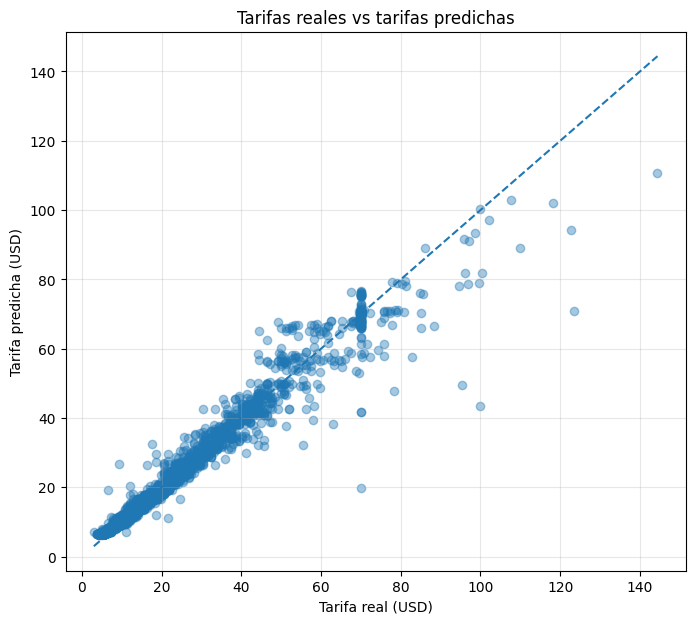

In [30]:
# Tomar una muestra de las predicciones

muestra_predicciones = (
    predicciones
    .select("fare_amount", "prediction")
    .sample(False, 0.05, seed=42)
    .limit(5000)
    .toPandas()
)

plt.figure(figsize=(8,7))

plt.scatter(
    muestra_predicciones["fare_amount"],
    muestra_predicciones["prediction"],
    alpha=0.4
)

# Línea de predicción perfecta
minimo = np.min([
    muestra_predicciones["fare_amount"].min(),
    muestra_predicciones["prediction"].min()
])

maximo = np.max([
    muestra_predicciones["fare_amount"].max(),
    muestra_predicciones["prediction"].max()
])

plt.plot(
    [minimo, maximo],
    [minimo, maximo],
    linestyle="--"
)

plt.title("Tarifas reales vs tarifas predichas")
plt.xlabel("Tarifa real (USD)")
plt.ylabel("Tarifa predicha (USD)")

plt.grid(alpha=0.3)
plt.show()

### Predicciones

In [23]:
resultado = predicciones.withColumn(
    "error_absoluto",
    abs(col("fare_amount") - col("prediction"))
)

# Mostrar los 15 errores más grandes
resultado.select(
    "fare_amount",
    "prediction",
    "error_absoluto",
    "trip_distance",
    "trip_duration_min"
).orderBy(
    col("error_absoluto").desc()
).show(15, truncate=False)

+-----------+-----------------+------------------+-------------+------------------+
|fare_amount|prediction       |error_absoluto    |trip_distance|trip_duration_min |
+-----------+-----------------+------------------+-------------+------------------+
|150.0      |44.09388324657298|105.90611675342703|8.09         |17.066666666666666|
|149.0      |45.86598644460882|103.13401355539118|9.87         |36.3              |
|150.0      |58.60076388121239|91.39923611878761 |11.62        |27.516666666666666|
|120.0      |30.17685346123115|89.82314653876885 |6.9          |24.3              |
|120.0      |34.26364180486892|85.73635819513109 |7.0          |9.266666666666667 |
|14.9       |98.58736713754261|83.68736713754261 |21.1         |42.833333333333336|
|150.0      |68.20191744750987|81.79808255249013 |14.38        |83.26666666666667 |
|150.0      |70.68486741093975|79.31513258906025 |15.3         |32.6              |
|140.0      |63.89948986644968|76.10051013355033 |11.81        |80.4        

### Importancia de Características

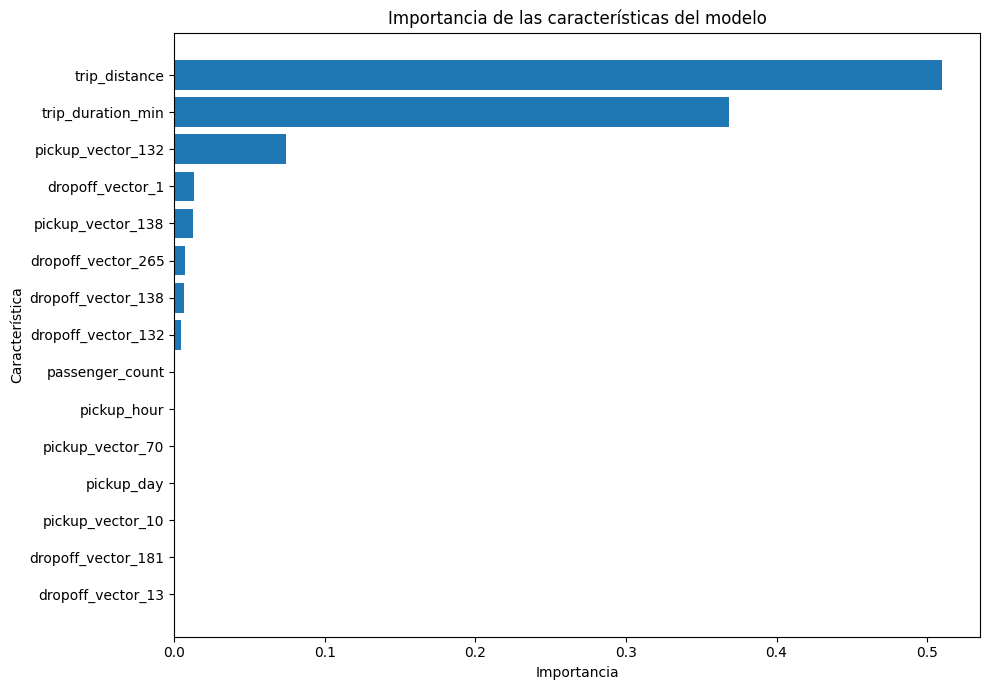

In [24]:
# Recuperar el Random Forest entrenado

rf_entrenado = modelo.stages[-1]

importancias = rf_entrenado.featureImportances.toArray()

# Obtener los nombres reales de las características
# a partir de los metadatos del vector features

metadata = predicciones.schema["features"].metadata

atributos = metadata["ml_attr"]["attrs"]

nombres_features = {}

for grupo in atributos.values():
    for atributo in grupo:
        nombres_features[atributo["idx"]] = atributo["name"]

# Asociar cada importancia con su característica

resultados_importancia = [
    (
        nombres_features.get(i, f"feature_{i}"),
        float(importancias[i])
    )
    for i in range(len(importancias))
]

# Ordenar de mayor a menor importancia
resultados_importancia.sort(
    key=lambda x: x[1],
    reverse=True
)

# Mostrar las 15 características más importantes
top_features = resultados_importancia[:15]

nombres = [x[0] for x in top_features]
valores = [x[1] for x in top_features]

plt.figure(figsize=(10,7))

plt.barh(nombres[::-1], valores[::-1])

plt.title("Importancia de las características del modelo")
plt.xlabel("Importancia")
plt.ylabel("Característica")

plt.tight_layout()
plt.show()